In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

df.shape

(6267, 44)

In [2]:
cortes_radius_valley = []

# 0. Muestra inicial
df0 = df.copy()

cortes_radius_valley.append({
    "corte": "muestra inicial",
    "N_planetas": len(df0)
})

# 1. Radio disponible
df1 = df0[df0["pl_rade"].notna()].copy()

cortes_radius_valley.append({
    "corte": "+ pl_rade disponible",
    "N_planetas": len(df1)
})

# 2. Rango de radio: 1 < Rp < 4
df2 = df1[
    (df1["pl_rade"] > 1.0) &
    (df1["pl_rade"] < 4.0)
].copy()

cortes_radius_valley.append({
    "corte": "1 < Rp < 4 R_earth",
    "N_planetas": len(df2)
})

# 3. Masa estelar disponible
df3 = df2[df2["st_mass"].notna()].copy()

cortes_radius_valley.append({
    "corte": "+ st_mass disponible",
    "N_planetas": len(df3)
})

# 4. Temperatura efectiva disponible
df4 = df3[df3["st_teff"].notna()].copy()

cortes_radius_valley.append({
    "corte": "+ st_teff disponible",
    "N_planetas": len(df4)
})

# 5. Metalicidad disponible
df5 = df4[df4["st_met"].notna()].copy()

cortes_radius_valley.append({
    "corte": "+ st_met disponible",
    "N_planetas": len(df5)
})

# 6. Periodo orbital disponible
df6 = df5[df5["pl_orbper"].notna()].copy()

cortes_radius_valley.append({
    "corte": "+ pl_orbper disponible",
    "N_planetas": len(df6)
})

# 7. Radio estelar disponible
df_radius_valley = df6[df6["st_rad"].notna()].copy()

cortes_radius_valley.append({
    "corte": "+ st_rad disponible",
    "N_planetas": len(df_radius_valley)
})

tabla_cortes_radius_valley = pd.DataFrame(cortes_radius_valley)

tabla_cortes_radius_valley["N_removidos"] = (
    tabla_cortes_radius_valley["N_planetas"].shift(1) -
    tabla_cortes_radius_valley["N_planetas"]
)

tabla_cortes_radius_valley["N_removidos"] = (
    tabla_cortes_radius_valley["N_removidos"]
    .fillna(0)
    .astype(int)
)

tabla_cortes_radius_valley["porcentaje_restante"] = (
    100 * tabla_cortes_radius_valley["N_planetas"] /
    tabla_cortes_radius_valley.loc[0, "N_planetas"]
).round(2)

tabla_cortes_radius_valley

,corte,N_planetas,N_removidos,porcentaje_restante
0,muestra inicial,6267,0,100.00
1,+ pl_rade disponible,6223,44,99.30
2,1 < Rp < 4 R_earth,3592,2631,57.32
3,+ st_mass disponible,3592,0,57.32
4,+ st_teff disponible,3539,53,56.47
5,+ st_met disponible,3359,180,53.60
6,+ pl_orbper disponible,3359,0,53.60
7,+ st_rad disponible,3357,2,53.57


In [3]:
df_radius_valley.to_csv(
    "../data_processed/06_muestra_radius_valley.csv",
    index=False
)

tabla_cortes_radius_valley.to_csv(
    "../tables/tabla_cortes_muestra_radius_valley.csv",
    index=False
)

df_radius_valley.shape

(3357, 44)

In [4]:
tabla_metodos_radius_valley = (
    df_radius_valley["discoverymethod"]
    .value_counts()
    .reset_index()
)

tabla_metodos_radius_valley.columns = [
    "metodo_descubrimiento",
    "N_planetas"
]

tabla_metodos_radius_valley["porcentaje"] = (
    100 * tabla_metodos_radius_valley["N_planetas"] /
    tabla_metodos_radius_valley["N_planetas"].sum()
).round(2)

tabla_metodos_radius_valley.to_csv(
    "../tables/tabla_metodos_muestra_radius_valley.csv",
    index=False
)

tabla_metodos_radius_valley

,metodo_descubrimiento,N_planetas,porcentaje
0,Transit,3116,92.82
1,Radial Velocity,222,6.61
2,Transit Timing Variations,19,0.57


In [5]:
def clasificar_facility(facility):
    facility = str(facility).lower()
    
    if "kepler" in facility:
        return "Kepler"
    elif "tess" in facility:
        return "TESS"
    else:
        return "otros"

df_radius_valley["grupo_facility"] = df_radius_valley["disc_facility"].apply(
    clasificar_facility
)

tabla_facility_radius_valley = (
    df_radius_valley["grupo_facility"]
    .value_counts()
    .reset_index()
)

tabla_facility_radius_valley.columns = [
    "grupo_facility",
    "N_planetas"
]

tabla_facility_radius_valley["porcentaje"] = (
    100 * tabla_facility_radius_valley["N_planetas"] /
    tabla_facility_radius_valley["N_planetas"].sum()
).round(2)

tabla_facility_radius_valley.to_csv(
    "../tables/tabla_facility_muestra_radius_valley.csv",
    index=False
)

tabla_facility_radius_valley

,grupo_facility,N_planetas,porcentaje
0,Kepler,2300,68.51
1,otros,660,19.66
2,TESS,397,11.83


In [6]:
variables_radius_valley = [
    "pl_rade",
    "pl_orbper",
    "st_mass",
    "st_teff",
    "st_met",
    "st_rad"
]

resumen_variables_radius_valley = (
    df_radius_valley[variables_radius_valley]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .T
)

resumen_variables_radius_valley = resumen_variables_radius_valley[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(4)

resumen_variables_radius_valley.to_csv(
    "../tables/resumen_variables_muestra_radius_valley.csv"
)

resumen_variables_radius_valley

,count,mean,std,min,25%,50%,75%,max
pl_rade,3357.0,2.1838,0.7216,1.0090,1.5600,2.1500,2.690,3.990
pl_orbper,3357.0,23.5171,65.4434,0.2242,4.9389,10.4755,21.677,2946.000
st_mass,3357.0,0.8820,0.2383,0.0898,0.7800,0.9100,1.030,2.018
st_teff,3357.0,5283.7872,817.8433,2566.0000,4919.0000,5513.0000,5858.000,8500.000
st_met,3357.0,-0.0093,0.1640,-0.9500,-0.0900,0.0000,0.080,0.560
st_rad,3357.0,0.9223,0.3294,0.1190,0.7400,0.8900,1.084,3.380


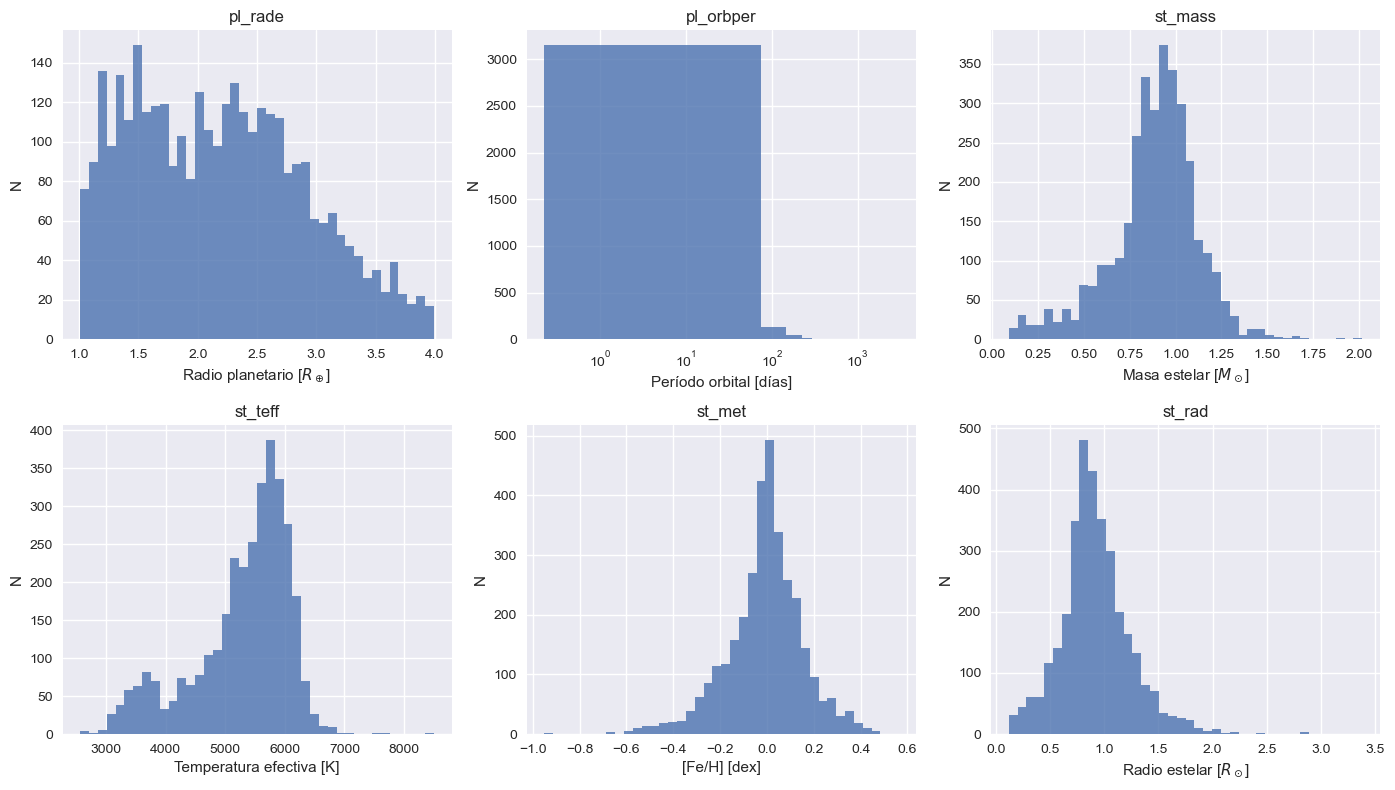

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes = axes.flatten()

variables_plot = [
    ("pl_rade", "Radio planetario [$R_\\oplus$]", False),
    ("pl_orbper", "Período orbital [días]", True),
    ("st_mass", "Masa estelar [$M_\\odot$]", False),
    ("st_teff", "Temperatura efectiva [K]", False),
    ("st_met", "[Fe/H] [dex]", False),
    ("st_rad", "Radio estelar [$R_\\odot$]", False),
]

for ax, (var, label, logx) in zip(axes, variables_plot):
    ax.hist(
        df_radius_valley[var].dropna(),
        bins=40,
        alpha=0.8
    )
    
    if logx:
        ax.set_xscale("log")
    
    ax.set_xlabel(label)
    ax.set_ylabel("N")
    ax.set_title(var)

plt.tight_layout()
plt.savefig(
    "../figures/distribuciones_muestra_radius_valley.png",
    dpi=300
)

plt.show()

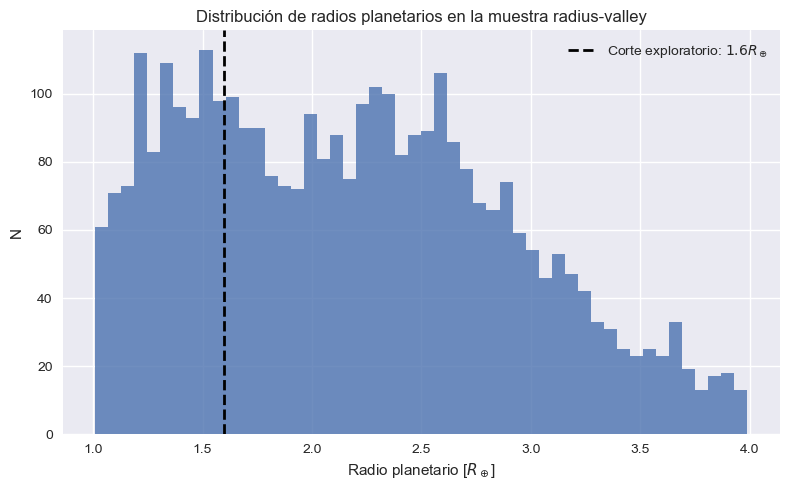

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_radius_valley["pl_rade"],
    bins=50,
    alpha=0.8
)

plt.axvline(
    1.6,
    color="black",
    linestyle="--",
    linewidth=2,
    label=r"Corte exploratorio: $1.6 R_\oplus$"
)

plt.xlabel(r"Radio planetario [$R_\oplus$]")
plt.ylabel("N")
plt.title("Distribución de radios planetarios en la muestra radius-valley")
plt.legend()

plt.tight_layout()
plt.savefig(
    "../figures/hist_radio_planetario_radius_valley.png",
    dpi=300
)

plt.show()

In [9]:
df_radius_valley["sub_neptune"] = (df_radius_valley["pl_rade"] > 1.6).astype(int)

df_radius_valley["clase_rv"] = np.where(
    df_radius_valley["pl_rade"] <= 1.6,
    "super_Earth",
    "sub_Neptune"
)

tabla_clase_radius_valley = (
    df_radius_valley["clase_rv"]
    .value_counts()
    .reset_index()
)

tabla_clase_radius_valley.columns = ["clase_rv", "N_planetas"]

tabla_clase_radius_valley["porcentaje"] = (
    100 * tabla_clase_radius_valley["N_planetas"] /
    tabla_clase_radius_valley["N_planetas"].sum()
).round(2)

tabla_clase_radius_valley.to_csv(
    "../tables/tabla_clase_radius_valley_1p6.csv",
    index=False
)

tabla_clase_radius_valley

,clase_rv,N_planetas,porcentaje
0,sub_Neptune,2450,72.98
1,super_Earth,907,27.02


In [10]:
df_radius_valley["st_mass_bin"] = pd.qcut(
    df_radius_valley["st_mass"],
    q=4,
    labels=["Mstar_Q1_baja", "Mstar_Q2", "Mstar_Q3", "Mstar_Q4_alta"]
)

df_radius_valley["st_teff_bin"] = pd.qcut(
    df_radius_valley["st_teff"],
    q=4,
    labels=["Teff_Q1_fria", "Teff_Q2", "Teff_Q3", "Teff_Q4_caliente"]
)


def resumen_fraccion_sub_neptune(df_base, columna_bin):
    tabla = (
        df_base
        .groupby(columna_bin, observed=True)["sub_neptune"]
        .agg(
            N_planetas="count",
            fraccion_sub_neptune="mean"
        )
        .reset_index()
    )
    
    tabla["porcentaje_sub_neptune"] = (
        100 * tabla["fraccion_sub_neptune"]
    ).round(2)
    
    tabla["agrupacion"] = columna_bin
    
    tabla = tabla.rename(columns={columna_bin: "grupo"})
    
    return tabla[
        ["agrupacion", "grupo", "N_planetas", "fraccion_sub_neptune", "porcentaje_sub_neptune"]
    ]


tabla_fraccion_sub_neptune_bins = pd.concat(
    [
        resumen_fraccion_sub_neptune(df_radius_valley, "st_mass_bin"),
        resumen_fraccion_sub_neptune(df_radius_valley, "st_teff_bin")
    ],
    ignore_index=True
)

tabla_fraccion_sub_neptune_bins.to_csv(
    "../tables/tabla_fraccion_sub_neptune_por_mstar_teff.csv",
    index=False
)

tabla_fraccion_sub_neptune_bins

,agrupacion,grupo,N_planetas,fraccion_sub_neptune,porcentaje_sub_neptune
0,st_mass_bin,Mstar_Q1_baja,861,0.646922,64.69
1,st_mass_bin,Mstar_Q2,838,0.730310,73.03
2,st_mass_bin,Mstar_Q3,859,0.781141,78.11
3,st_mass_bin,Mstar_Q4_alta,799,0.763454,76.35
4,st_teff_bin,Teff_Q1_fria,841,0.644471,64.45
5,st_teff_bin,Teff_Q2,841,0.744352,74.44
6,st_teff_bin,Teff_Q3,837,0.769415,76.94
7,st_teff_bin,Teff_Q4_caliente,838,0.761337,76.13


In [11]:
import statsmodels.api as sm

df_radius_valley_modelo = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_teff"].notna() &
    df_radius_valley["st_met"].notna() &
    df_radius_valley["pl_orbper"].notna()
].copy()

df_radius_valley_modelo["log_orbper"] = np.log10(
    df_radius_valley_modelo["pl_orbper"]
)

X_rv = df_radius_valley_modelo[
    [
        "st_mass",
        "st_teff",
        "st_met",
        "log_orbper"
    ]
]

X_rv = sm.add_constant(X_rv)

y_rv = df_radius_valley_modelo["sub_neptune"]

modelo_rv_logit = sm.Logit(y_rv, X_rv).fit()

modelo_rv_logit.summary()

Optimization terminated successfully.
         Current function value: 0.498871
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            sub_neptune   No. Observations:                 3357
Model:                          Logit   Df Residuals:                     3352
Method:                           MLE   Df Model:                            4
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1449
Time:                        11:08:29   Log-Likelihood:                -1674.7
converged:                       True   LL-Null:                       -1958.6
Covariance Type:            nonrobust   LLR p-value:                1.444e-121
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.8148      0.415     -1.962      0.050      -1.629      -0.001
st_mass        1.5590      0.613      2.543      0.011       0.357       2.761
st_teff       -0.0003      0.000     -1.566      0.117      -0.001    6.69e-05
st_met         1.0720      0.292      3.669      0.000       0.499       1.645
log_orbper     2.0105      0.103     19.608      0.000       1.810       2.211
==============================================================================
"""

En la muestra 1 < Rp < 4 R⊕, la probabilidad de que un planeta sea clasificado como sub-Neptuno aumenta con la masa estelar, la metalicidad y el período orbital. La temperatura efectiva no mantiene una asociación significativa cuando se controla simultáneamente por masa estelar, metalicidad y período.

In [12]:
params_rv = modelo_rv_logit.params
conf_rv = modelo_rv_logit.conf_int()

tabla_or_rv_logit = pd.DataFrame({
    "variable": params_rv.index,
    "coef": params_rv.values,
    "p_value": modelo_rv_logit.pvalues.values,
    "odds_ratio": np.exp(params_rv.values),
    "OR_IC95_low": np.exp(conf_rv[0].values),
    "OR_IC95_high": np.exp(conf_rv[1].values)
})

tabla_or_rv_logit.to_csv(
    "../tables/tabla_logit_radius_valley_odds_ratios.csv",
    index=False
)

tabla_or_rv_logit.round(4)

,variable,coef,p_value,odds_ratio,OR_IC95_low,OR_IC95_high
0,const,-0.8148,0.0497,0.4427,0.1962,0.9991
1,st_mass,1.5590,0.0110,4.7542,1.4295,15.8115
2,st_teff,-0.0003,0.1173,0.9997,0.9994,1.0001
3,st_met,1.0720,0.0002,2.9212,1.6477,5.1790
4,log_orbper,2.0105,0.0000,7.4671,6.1076,9.1292


En la muestra de planetas con 1 < Rp < 4 R⊕, la probabilidad de que un planeta sea clasificado como sub-Neptuno aumenta significativamente con la masa estelar, la metalicidad y el período orbital. En el modelo logístico, st_mass presenta OR = 4.75 (IC95% = [1.43, 15.81], p = 0.011), st_met presenta OR = 2.92 (IC95% = [1.65, 5.18], p < 0.001) y log_orbper presenta OR = 7.47 (IC95% = [6.11, 9.13], p < 0.001). La temperatura efectiva no mantiene una asociación significativa al controlar por estas variables.

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif_rv = df_radius_valley_modelo[
    [
        "st_mass",
        "st_teff",
        "st_met",
        "log_orbper"
    ]
].copy()

X_vif_rv = sm.add_constant(X_vif_rv)

tabla_vif_rv = pd.DataFrame({
    "variable": X_vif_rv.columns,
    "VIF": [
        variance_inflation_factor(X_vif_rv.values, i)
        for i in range(X_vif_rv.shape[1])
    ]
})

tabla_vif_rv

,variable,VIF
0,const,96.889472
1,st_mass,10.853788
2,st_teff,10.132555
3,st_met,1.328742
4,log_orbper,1.039248


In [14]:
# Modelo A: masa estelar, sin Teff
X_rv_mass = df_radius_valley_modelo[
    [
        "st_mass",
        "st_met",
        "log_orbper"
    ]
]

X_rv_mass = sm.add_constant(X_rv_mass)

modelo_rv_mass = sm.Logit(
    df_radius_valley_modelo["sub_neptune"],
    X_rv_mass
).fit()


# Modelo B: Teff, sin masa estelar
X_rv_teff = df_radius_valley_modelo[
    [
        "st_teff",
        "st_met",
        "log_orbper"
    ]
]

X_rv_teff = sm.add_constant(X_rv_teff)

modelo_rv_teff = sm.Logit(
    df_radius_valley_modelo["sub_neptune"],
    X_rv_teff
).fit()


comparacion_modelos_rv = pd.DataFrame({
    "modelo": [
        "st_mass + st_met + log_orbper",
        "st_teff + st_met + log_orbper",
        "st_mass + st_teff + st_met + log_orbper"
    ],
    "N": [
        int(modelo_rv_mass.nobs),
        int(modelo_rv_teff.nobs),
        int(modelo_rv_logit.nobs)
    ],
    "pseudo_R2": [
        modelo_rv_mass.prsquared,
        modelo_rv_teff.prsquared,
        modelo_rv_logit.prsquared
    ],
    "AIC": [
        modelo_rv_mass.aic,
        modelo_rv_teff.aic,
        modelo_rv_logit.aic
    ],
    "BIC": [
        modelo_rv_mass.bic,
        modelo_rv_teff.bic,
        modelo_rv_logit.bic
    ],
    "LLR_p_value": [
        modelo_rv_mass.llr_pvalue,
        modelo_rv_teff.llr_pvalue,
        modelo_rv_logit.llr_pvalue
    ]
})

comparacion_modelos_rv.round(4)

Optimization terminated successfully.
         Current function value: 0.499240
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.499858
         Iterations 6


,modelo,N,pseudo_R2,AIC,BIC,LLR_p_value
0,st_mass + st_met + log_orbper,3357,0.1443,3359.8993,3384.3745,0.0
1,st_teff + st_met + log_orbper,3357,0.1433,3364.0471,3388.5223,0.0
2,st_mass + st_teff + st_met + log_orbper,3357,0.1449,3359.4174,3390.0114,0.0


Debido a la fuerte colinealidad entre masa estelar y temperatura efectiva, se compararon modelos alternativos que incluyen una de estas variables a la vez. El modelo con masa estelar, metalicidad y período orbital presentó un ajuste ligeramente mejor que el modelo con temperatura efectiva según AIC y BIC, mientras que incluir simultáneamente masa estelar y temperatura efectiva produjo una mejora mínima en pseudo R² y AIC, pero aumentó el BIC. Por esta razón, se adoptó como modelo principal el modelo con masa estelar, metalicidad y período orbital.

In [15]:
params_rv_mass = modelo_rv_mass.params
conf_rv_mass = modelo_rv_mass.conf_int()

tabla_or_rv_mass = pd.DataFrame({
    "variable": params_rv_mass.index,
    "coef": params_rv_mass.values,
    "p_value": modelo_rv_mass.pvalues.values,
    "odds_ratio": np.exp(params_rv_mass.values),
    "OR_IC95_low": np.exp(conf_rv_mass[0].values),
    "OR_IC95_high": np.exp(conf_rv_mass[1].values)
})

tabla_or_rv_mass.to_csv(
    "../tables/tabla_logit_radius_valley_modelo_principal_mass.csv",
    index=False
)

tabla_or_rv_mass.round(4)

,variable,coef,p_value,odds_ratio,OR_IC95_low,OR_IC95_high
0,const,-1.4052,0.0000,0.2453,0.1736,0.3467
1,st_mass,0.6456,0.0004,1.9071,1.3312,2.7320
2,st_met,1.2501,0.0000,3.4907,2.0586,5.9190
3,log_orbper,1.9996,0.0000,7.3858,6.0454,9.0234


# bloque 2 (distribucion de radios por masa estelar)

In [16]:
df_radius_valley["mstar_bin_3"] = pd.qcut(
    df_radius_valley["st_mass"],
    q=3,
    labels=["Mstar_baja", "Mstar_media", "Mstar_alta"]
)

limites_mstar_bins = (
    df_radius_valley
    .groupby("mstar_bin_3", observed=True)["st_mass"]
    .agg(
        N="count",
        min_Mstar="min",
        mediana_Mstar="median",
        max_Mstar="max"
    )
    .reset_index()
)

limites_mstar_bins

,mstar_bin_3,N,min_Mstar,mediana_Mstar,max_Mstar
0,Mstar_baja,1149,0.0898,0.686,0.830
1,Mstar_media,1089,0.8310,0.910,0.981
2,Mstar_alta,1119,0.9820,1.080,2.018


In [17]:
tabla_rp_por_mstar = (
    df_radius_valley
    .groupby("mstar_bin_3", observed=True)
    .agg(
        N_planetas=("pl_rade", "count"),
        Mstar_min=("st_mass", "min"),
        Mstar_mediana=("st_mass", "median"),
        Mstar_max=("st_mass", "max"),
        Rp_mediana=("pl_rade", "median"),
        Rp_Q1=("pl_rade", lambda x: x.quantile(0.25)),
        Rp_Q3=("pl_rade", lambda x: x.quantile(0.75)),
        N_super_Earth=("sub_neptune", lambda x: (x == 0).sum()),
        N_sub_Neptune=("sub_neptune", lambda x: (x == 1).sum()),
        fraccion_super_Earth=("sub_neptune", lambda x: (x == 0).mean()),
        fraccion_sub_Neptune=("sub_neptune", "mean")
    )
    .reset_index()
)

tabla_rp_por_mstar["Rp_IQR"] = tabla_rp_por_mstar["Rp_Q3"] - tabla_rp_por_mstar["Rp_Q1"]

tabla_rp_por_mstar["ratio_subN_superEarth"] = (
    tabla_rp_por_mstar["N_sub_Neptune"] /
    tabla_rp_por_mstar["N_super_Earth"]
)

tabla_rp_por_mstar = tabla_rp_por_mstar[
    [
        "mstar_bin_3",
        "N_planetas",
        "Mstar_min",
        "Mstar_mediana",
        "Mstar_max",
        "Rp_mediana",
        "Rp_Q1",
        "Rp_Q3",
        "Rp_IQR",
        "N_super_Earth",
        "N_sub_Neptune",
        "fraccion_super_Earth",
        "fraccion_sub_Neptune",
        "ratio_subN_superEarth"
    ]
].round(4)

tabla_rp_por_mstar.to_csv(
    "../tables/tabla_rp_por_bins_masa_estelar.csv",
    index=False
)

tabla_rp_por_mstar

,mstar_bin_3,N_planetas,Mstar_min,Mstar_mediana,Mstar_max,Rp_mediana,Rp_Q1,Rp_Q3,Rp_IQR,N_super_Earth,N_sub_Neptune,fraccion_super_Earth,fraccion_sub_Neptune,ratio_subN_superEarth
0,Mstar_baja,1149,0.0898,0.686,0.830,1.96,1.44,2.467,1.027,390,759,0.3394,0.6606,1.9462
1,Mstar_media,1089,0.8310,0.910,0.981,2.27,1.64,2.770,1.130,255,834,0.2342,0.7658,3.2706
2,Mstar_alta,1119,0.9820,1.080,2.018,2.27,1.63,2.839,1.209,262,857,0.2341,0.7659,3.2710


Las estrellas de baja masa tienen una fracción menor de sub-Neptunos.
Las estrellas de masa media y alta tienen fracciones muy parecidas y más altas.

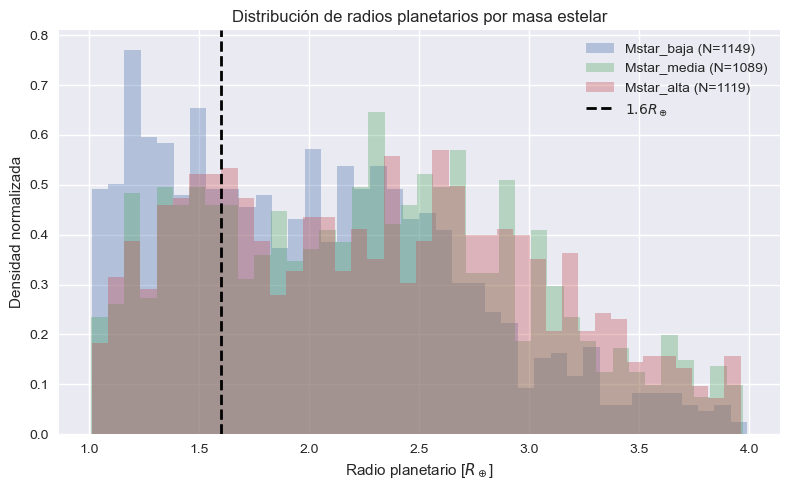

In [18]:
plt.figure(figsize=(8, 5))

orden_mstar_bins = ["Mstar_baja", "Mstar_media", "Mstar_alta"]

for bin_name in orden_mstar_bins:
    subset = df_radius_valley[df_radius_valley["mstar_bin_3"] == bin_name]
    
    plt.hist(
        subset["pl_rade"],
        bins=40,
        density=True,
        alpha=0.35,
        label=f"{bin_name} (N={len(subset)})"
    )

plt.axvline(
    1.6,
    color="black",
    linestyle="--",
    linewidth=2,
    label=r"$1.6 R_\oplus$"
)

plt.xlabel(r"Radio planetario [$R_\oplus$]")
plt.ylabel("Densidad normalizada")
plt.title("Distribución de radios planetarios por masa estelar")
plt.legend()

plt.tight_layout()
plt.savefig(
    "../figures/distribucion_rp_por_masa_estelar.png",
    dpi=300
)

plt.show()

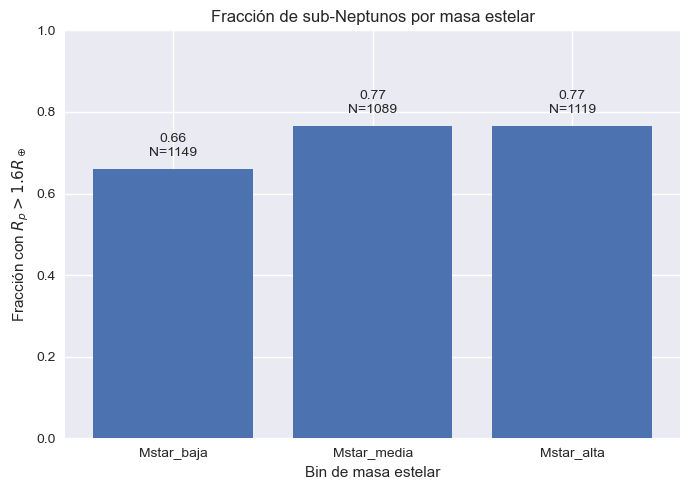

In [19]:
plt.figure(figsize=(7, 5))

plt.bar(
    tabla_rp_por_mstar["mstar_bin_3"],
    tabla_rp_por_mstar["fraccion_sub_Neptune"]
)

plt.ylabel(r"Fracción con $R_p > 1.6 R_\oplus$")
plt.xlabel("Bin de masa estelar")
plt.title("Fracción de sub-Neptunos por masa estelar")
plt.ylim(0, 1)

for i, row in tabla_rp_por_mstar.iterrows():
    plt.text(
        i,
        row["fraccion_sub_Neptune"] + 0.025,
        f"{row['fraccion_sub_Neptune']:.2f}\nN={int(row['N_planetas'])}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(
    "../figures/fraccion_sub_neptune_por_masa_estelar.png",
    dpi=300
)

plt.show()

In [20]:
df_rv_modelo_principal = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_met"].notna() &
    df_radius_valley["pl_orbper"].notna()
].copy()

df_rv_modelo_principal["log_orbper"] = np.log10(
    df_rv_modelo_principal["pl_orbper"]
)

df_rv_modelo_principal[
    ["sub_neptune", "pl_rade", "st_mass", "st_met", "pl_orbper", "log_orbper"]
].describe().T

,count,mean,std,min,25%,50%,75%,max
sub_neptune,3357.0,0.729818,0.444120,0.000000,0.000000,1.000000,1.000000,1.000000
pl_rade,3357.0,2.183756,0.721615,1.009000,1.560000,2.150000,2.690000,3.990000
st_mass,3357.0,0.881998,0.238327,0.089800,0.780000,0.910000,1.030000,2.018000
st_met,3357.0,-0.009302,0.164019,-0.950000,-0.090000,0.000000,0.080000,0.560000
pl_orbper,3357.0,23.517135,65.443441,0.224196,4.938864,10.475464,21.676975,2946.000000
log_orbper,3357.0,1.031816,0.517896,-0.649373,0.693627,1.020173,1.335999,3.469233


In [21]:
import statsmodels.api as sm

X_rv_principal = df_rv_modelo_principal[
    [
        "st_mass",
        "st_met",
        "log_orbper"
    ]
]

X_rv_principal = sm.add_constant(X_rv_principal)

y_rv_principal = df_rv_modelo_principal["sub_neptune"]

modelo_rv_principal = sm.Logit(
    y_rv_principal,
    X_rv_principal
).fit()

modelo_rv_principal.summary()

Optimization terminated successfully.
         Current function value: 0.499240
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            sub_neptune   No. Observations:                 3357
Model:                          Logit   Df Residuals:                     3353
Method:                           MLE   Df Model:                            3
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1443
Time:                        11:08:30   Log-Likelihood:                -1675.9
converged:                       True   LL-Null:                       -1958.6
Covariance Type:            nonrobust   LLR p-value:                3.331e-122
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4052      0.176     -7.962      0.000      -1.751      -1.059
st_mass        0.6456      0.183      3.520      0.000       0.286       1.005
st_met         1.2501      0.269      4.640      0.000       0.722       1.778
log_orbper     1.9996      0.102     19.570      0.000       1.799       2.200
==============================================================================
"""

In [22]:
df_radius_valley["pl_insol"].notna().sum(), len(df_radius_valley)

(3192, 3357)

In [23]:
porcentaje_insol = 100 * df_radius_valley["pl_insol"].notna().mean()

print(f"Planetas con pl_insol disponible: {df_radius_valley['pl_insol'].notna().sum()}")
print(f"Total muestra radius-valley: {len(df_radius_valley)}")
print(f"Porcentaje disponible: {porcentaje_insol:.2f}%")

Planetas con pl_insol disponible: 3192
Total muestra radius-valley: 3357
Porcentaje disponible: 95.08%


In [24]:
df_insol_modelo = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["pl_insol"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_met"].notna()
].copy()

df_insol_modelo = df_insol_modelo[df_insol_modelo["pl_insol"] > 0].copy()

df_insol_modelo["log_insol"] = np.log10(df_insol_modelo["pl_insol"])

df_insol_modelo.shape

(3192, 51)

In [25]:
X_insol = df_insol_modelo[
    [
        "log_insol",
        "st_mass",
        "st_met"
    ]
]

X_insol = sm.add_constant(X_insol)

y_insol = df_insol_modelo["sub_neptune"]

modelo_rv_insol = sm.Logit(y_insol, X_insol).fit()

modelo_rv_insol.summary()

Optimization terminated successfully.
         Current function value: 0.499899
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            sub_neptune   No. Observations:                 3192
Model:                          Logit   Df Residuals:                     3188
Method:                           MLE   Df Model:                            3
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1384
Time:                        11:08:30   Log-Likelihood:                -1595.7
converged:                       True   LL-Null:                       -1851.9
Covariance Type:            nonrobust   LLR p-value:                9.617e-111
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3458      0.171      2.022      0.043       0.011       0.681
log_insol     -1.4416      0.077    -18.758      0.000      -1.592      -1.291
st_mass        3.9310      0.245     16.038      0.000       3.451       4.411
st_met         0.6918      0.273      2.537      0.011       0.157       1.226
==============================================================================
"""

Al reemplazar el período orbital por la insolación planetaria, se encuentra que la probabilidad de que un planeta sea clasificado como sub-Neptuno disminuye significativamente con la irradiación recibida. El coeficiente de log_insol es negativo y altamente significativo (coef = -1.442, IC95% = [-1.592, -1.291], p < 0.001). Esto es consistente con un escenario en el que planetas más irradiados tienen menor probabilidad de conservar envolturas volátiles y, por tanto, menor probabilidad de encontrarse por encima del corte exploratorio de 1.6 R⊕.

In [26]:
params_insol = modelo_rv_insol.params
conf_insol = modelo_rv_insol.conf_int()

tabla_or_rv_insol = pd.DataFrame({
    "variable": params_insol.index,
    "coef": params_insol.values,
    "p_value": modelo_rv_insol.pvalues.values,
    "odds_ratio": np.exp(params_insol.values),
    "OR_IC95_low": np.exp(conf_insol[0].values),
    "OR_IC95_high": np.exp(conf_insol[1].values)
})

tabla_or_rv_insol.to_csv(
    "../tables/tabla_logit_radius_valley_insolacion.csv",
    index=False
)

tabla_or_rv_insol.round(4)

,variable,coef,p_value,odds_ratio,OR_IC95_low,OR_IC95_high
0,const,0.3458,0.0432,1.4131,1.0107,1.9756
1,log_insol,-1.4416,0.0000,0.2365,0.2035,0.2750
2,st_mass,3.9310,0.0000,50.9596,31.5199,82.3886
3,st_met,0.6918,0.0112,1.9972,1.1704,3.4081


In [27]:
OR_st_mass_0p1 = np.exp(modelo_rv_insol.params["st_mass"] * 0.1)

IC_st_mass = modelo_rv_insol.conf_int().loc["st_mass"]
OR_st_mass_0p1_low = np.exp(IC_st_mass[0] * 0.1)
OR_st_mass_0p1_high = np.exp(IC_st_mass[1] * 0.1)

print(f"OR st_mass por 0.1 M_sun = {OR_st_mass_0p1:.3f}")
print(f"IC95% = [{OR_st_mass_0p1_low:.3f}, {OR_st_mass_0p1_high:.3f}]")

OR st_mass por 0.1 M_sun = 1.482
IC95% = [1.412, 1.554]


In [28]:
OR_st_met_0p1 = np.exp(modelo_rv_insol.params["st_met"] * 0.1)

IC_st_met = modelo_rv_insol.conf_int().loc["st_met"]
OR_st_met_0p1_low = np.exp(IC_st_met[0] * 0.1)
OR_st_met_0p1_high = np.exp(IC_st_met[1] * 0.1)

print(f"OR st_met por 0.1 dex = {OR_st_met_0p1:.3f}")
print(f"IC95% = [{OR_st_met_0p1_low:.3f}, {OR_st_met_0p1_high:.3f}]")

OR st_met por 0.1 dex = 1.072
IC95% = [1.016, 1.130]


In [29]:
comparacion_modelos_periodo_insol = pd.DataFrame({
    "modelo": [
        "st_mass + st_met + log_orbper",
        "st_mass + st_met + log_insol"
    ],
    "N": [
        int(modelo_rv_principal.nobs),
        int(modelo_rv_insol.nobs)
    ],
    "pseudo_R2": [
        modelo_rv_principal.prsquared,
        modelo_rv_insol.prsquared
    ],
    "AIC": [
        modelo_rv_principal.aic,
        modelo_rv_insol.aic
    ],
    "BIC": [
        modelo_rv_principal.bic,
        modelo_rv_insol.bic
    ],
    "LLR_p_value": [
        modelo_rv_principal.llr_pvalue,
        modelo_rv_insol.llr_pvalue
    ]
})

comparacion_modelos_periodo_insol.to_csv(
    "../tables/comparacion_modelos_periodo_vs_insolacion.csv",
    index=False
)

comparacion_modelos_periodo_insol.round(4)

,modelo,N,pseudo_R2,AIC,BIC,LLR_p_value
0,st_mass + st_met + log_orbper,3357,0.1443,3359.8993,3384.3745,0.0
1,st_mass + st_met + log_insol,3192,0.1384,3199.3578,3223.6314,0.0


In [30]:
df_insol_modelo["insol_bin"] = pd.qcut(
    df_insol_modelo["log_insol"],
    q=4,
    labels=["insol_Q1_baja", "insol_Q2", "insol_Q3", "insol_Q4_alta"]
)

tabla_fraccion_sub_neptune_insol = (
    df_insol_modelo
    .groupby("insol_bin", observed=True)
    .agg(
        N_planetas=("sub_neptune", "count"),
        log_insol_min=("log_insol", "min"),
        log_insol_mediana=("log_insol", "median"),
        log_insol_max=("log_insol", "max"),
        fraccion_sub_Neptune=("sub_neptune", "mean")
    )
    .reset_index()
)

tabla_fraccion_sub_neptune_insol["porcentaje_sub_Neptune"] = (
    100 * tabla_fraccion_sub_neptune_insol["fraccion_sub_Neptune"]
).round(2)

tabla_fraccion_sub_neptune_insol.to_csv(
    "../tables/tabla_fraccion_sub_neptune_por_insolacion.csv",
    index=False
)

tabla_fraccion_sub_neptune_insol.round(4)

,insol_bin,N_planetas,log_insol_min,log_insol_mediana,log_insol_max,fraccion_sub_Neptune,porcentaje_sub_Neptune
0,insol_Q1_baja,798,-2.6383,0.8239,1.2710,0.8308,83.08
1,insol_Q2,798,1.2725,1.5726,1.8424,0.8371,83.71
2,insol_Q3,798,1.8426,2.0991,2.3467,0.7030,70.30
3,insol_Q4_alta,798,2.3481,2.7024,4.0074,0.5614,56.14


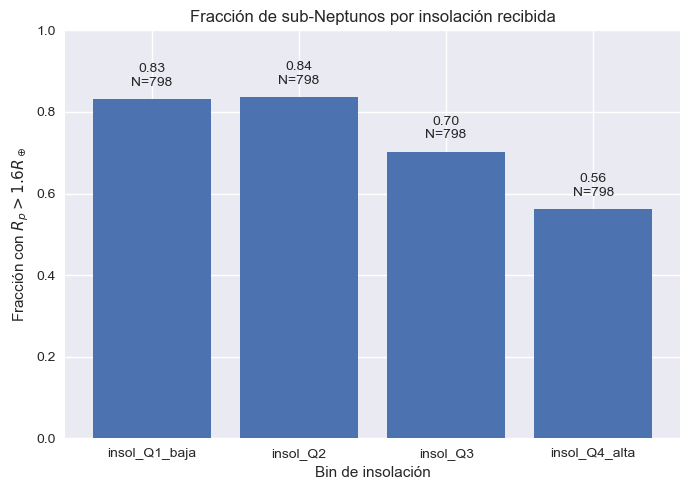

In [31]:
plt.figure(figsize=(7, 5))

plt.bar(
    tabla_fraccion_sub_neptune_insol["insol_bin"],
    tabla_fraccion_sub_neptune_insol["fraccion_sub_Neptune"]
)

plt.ylabel(r"Fracción con $R_p > 1.6 R_\oplus$")
plt.xlabel("Bin de insolación")
plt.title("Fracción de sub-Neptunos por insolación recibida")
plt.ylim(0, 1)

for i, row in tabla_fraccion_sub_neptune_insol.iterrows():
    plt.text(
        i,
        row["fraccion_sub_Neptune"] + 0.025,
        f"{row['fraccion_sub_Neptune']:.2f}\nN={int(row['N_planetas'])}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(
    "../figures/fraccion_sub_neptune_por_insolacion.png",
    dpi=300
)

plt.show()

In [32]:
df_radius_valley["teff_bin_3"] = pd.qcut(
    df_radius_valley["st_teff"],
    q=3,
    labels=["Teff_fria", "Teff_media", "Teff_caliente"]
)

limites_teff_bins = (
    df_radius_valley
    .groupby("teff_bin_3", observed=True)["st_teff"]
    .agg(
        N="count",
        min_Teff="min",
        mediana_Teff="median",
        max_Teff="max"
    )
    .reset_index()
)

limites_teff_bins

,teff_bin_3,N,min_Teff,mediana_Teff,max_Teff
0,Teff_fria,1121,2566.0,4486.0,5165.0
1,Teff_media,1118,5166.0,5513.0,5757.0
2,Teff_caliente,1118,5758.0,5989.0,8500.0


In [33]:
tabla_rp_por_teff = (
    df_radius_valley
    .groupby("teff_bin_3", observed=True)
    .agg(
        N_planetas=("pl_rade", "count"),
        Teff_min=("st_teff", "min"),
        Teff_mediana=("st_teff", "median"),
        Teff_max=("st_teff", "max"),
        Rp_mediana=("pl_rade", "median"),
        Rp_Q1=("pl_rade", lambda x: x.quantile(0.25)),
        Rp_Q3=("pl_rade", lambda x: x.quantile(0.75)),
        N_super_Earth=("sub_neptune", lambda x: (x == 0).sum()),
        N_sub_Neptune=("sub_neptune", lambda x: (x == 1).sum()),
        fraccion_super_Earth=("sub_neptune", lambda x: (x == 0).mean()),
        fraccion_sub_Neptune=("sub_neptune", "mean")
    )
    .reset_index()
)

tabla_rp_por_teff["Rp_IQR"] = tabla_rp_por_teff["Rp_Q3"] - tabla_rp_por_teff["Rp_Q1"]

tabla_rp_por_teff["ratio_subN_superEarth"] = (
    tabla_rp_por_teff["N_sub_Neptune"] /
    tabla_rp_por_teff["N_super_Earth"]
)

tabla_rp_por_teff = tabla_rp_por_teff[
    [
        "teff_bin_3",
        "N_planetas",
        "Teff_min",
        "Teff_mediana",
        "Teff_max",
        "Rp_mediana",
        "Rp_Q1",
        "Rp_Q3",
        "Rp_IQR",
        "N_super_Earth",
        "N_sub_Neptune",
        "fraccion_super_Earth",
        "fraccion_sub_Neptune",
        "ratio_subN_superEarth"
    ]
].round(4)

tabla_rp_por_teff.to_csv(
    "../tables/tabla_rp_por_bins_teff.csv",
    index=False
)

tabla_rp_por_teff

,teff_bin_3,N_planetas,Teff_min,Teff_mediana,Teff_max,Rp_mediana,Rp_Q1,Rp_Q3,Rp_IQR,N_super_Earth,N_sub_Neptune,fraccion_super_Earth,fraccion_sub_Neptune,ratio_subN_superEarth
0,Teff_fria,1121,2566.0,4486.0,5165.0,1.95,1.4400,2.4700,1.0300,384,737,0.3426,0.6574,1.9193
1,Teff_media,1118,5166.0,5513.0,5757.0,2.29,1.6600,2.7788,1.1188,255,863,0.2281,0.7719,3.3843
2,Teff_caliente,1118,5758.0,5989.0,8500.0,2.24,1.6208,2.8300,1.2092,268,850,0.2397,0.7603,3.1716


Al dividir la muestra en tres bins balanceados de temperatura efectiva, se observa que los planetas alrededor de estrellas frías presentan una menor fracción de sub-Neptunos. En el bin frío, la fracción de planetas con Rp > 1.6 R⊕ es 65.7%, mientras que aumenta a 77.2% y 76.0% en los bins de temperatura media y alta, respectivamente. Este patrón es muy similar al observado con masa estelar, lo cual es esperable dada la fuerte correlación entre Mstar y Teff.]

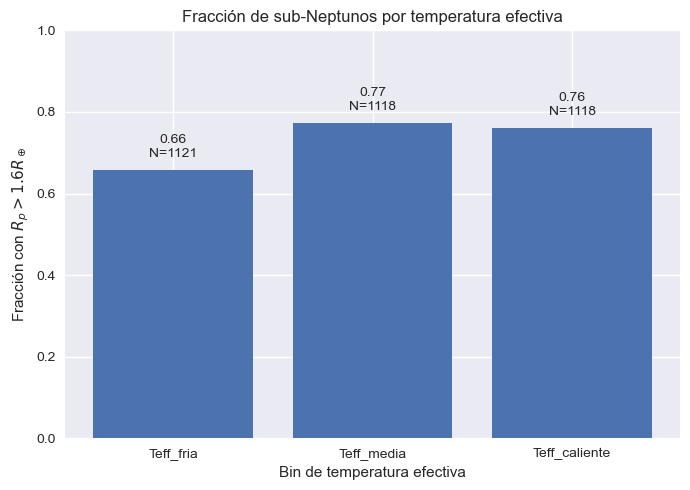

In [34]:
plt.figure(figsize=(7, 5))

plt.bar(
    tabla_rp_por_teff["teff_bin_3"],
    tabla_rp_por_teff["fraccion_sub_Neptune"]
)

plt.ylabel(r"Fracción con $R_p > 1.6 R_\oplus$")
plt.xlabel("Bin de temperatura efectiva")
plt.title("Fracción de sub-Neptunos por temperatura efectiva")
plt.ylim(0, 1)

for i, row in tabla_rp_por_teff.iterrows():
    plt.text(
        i,
        row["fraccion_sub_Neptune"] + 0.025,
        f"{row['fraccion_sub_Neptune']:.2f}\nN={int(row['N_planetas'])}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(
    "../figures/fraccion_sub_neptune_por_teff.png",
    dpi=300
)

plt.show()

In [35]:
variables_irradiacion = [
    "pl_insol",
    "pl_orbsmax",
    "pl_orbper",
    "st_mass",
    "st_rad",
    "st_teff"
]

disponibilidad_irradiacion = pd.DataFrame({
    "variable": variables_irradiacion,
    "N_disponibles": [
        df_radius_valley[v].notna().sum()
        for v in variables_irradiacion
    ],
    "N_faltantes": [
        df_radius_valley[v].isna().sum()
        for v in variables_irradiacion
    ],
    "porcentaje_disponible": [
        100 * df_radius_valley[v].notna().mean()
        for v in variables_irradiacion
    ]
}).round(2)

disponibilidad_irradiacion

,variable,N_disponibles,N_faltantes,porcentaje_disponible
0,pl_insol,3192,165,95.08
1,pl_orbsmax,3141,216,93.57
2,pl_orbper,3357,0,100.00
3,st_mass,3357,0,100.00
4,st_rad,3357,0,100.00
5,st_teff,3357,0,100.00


In [36]:
df_radius_valley["P_years"] = df_radius_valley["pl_orbper"] / 365.25

df_radius_valley["a_kepler_au"] = (
    df_radius_valley["st_mass"] * df_radius_valley["P_years"]**2
)**(1/3)

df_radius_valley["a_final_au"] = df_radius_valley["pl_orbsmax"].copy()

df_radius_valley["a_origen"] = np.where(
    df_radius_valley["pl_orbsmax"].notna(),
    "catalogado",
    "kepler_derivado"
)

df_radius_valley.loc[
    df_radius_valley["a_final_au"].isna(),
    "a_final_au"
] = df_radius_valley.loc[
    df_radius_valley["a_final_au"].isna(),
    "a_kepler_au"
]

tabla_origen_a = (
    df_radius_valley["a_origen"]
    .value_counts()
    .reset_index()
)

tabla_origen_a.columns = ["origen_a", "N_planetas"]

tabla_origen_a["porcentaje"] = (
    100 * tabla_origen_a["N_planetas"] / len(df_radius_valley)
).round(2)

tabla_origen_a

,origen_a,N_planetas,porcentaje
0,catalogado,3141,93.57
1,kepler_derivado,216,6.43


In [37]:
df_check_a = df_radius_valley[
    df_radius_valley["pl_orbsmax"].notna() &
    df_radius_valley["a_kepler_au"].notna() &
    (df_radius_valley["pl_orbsmax"] > 0) &
    (df_radius_valley["a_kepler_au"] > 0)
].copy()

df_check_a["ratio_a_catalog_kepler"] = (
    df_check_a["pl_orbsmax"] / df_check_a["a_kepler_au"]
)

df_check_a["log_ratio_a_catalog_kepler"] = np.log10(
    df_check_a["ratio_a_catalog_kepler"]
)

resumen_check_a = pd.DataFrame({
    "N": [len(df_check_a)],
    "ratio_mediana": [df_check_a["ratio_a_catalog_kepler"].median()],
    "ratio_Q1": [df_check_a["ratio_a_catalog_kepler"].quantile(0.25)],
    "ratio_Q3": [df_check_a["ratio_a_catalog_kepler"].quantile(0.75)],
    "ratio_min": [df_check_a["ratio_a_catalog_kepler"].min()],
    "ratio_max": [df_check_a["ratio_a_catalog_kepler"].max()],
    "abs_log_ratio_mediana": [df_check_a["log_ratio_a_catalog_kepler"].abs().median()]
}).round(4)

resumen_check_a

,N,ratio_mediana,ratio_Q1,ratio_Q3,ratio_min,ratio_max,abs_log_ratio_mediana
0,3141,1.0,0.9898,1.0093,0.568,3.702,0.0042


In [38]:
T_sun = 5772  # K

df_radius_valley["insol_calculada"] = (
    (df_radius_valley["st_rad"] ** 2) *
    (df_radius_valley["st_teff"] / T_sun) ** 4 *
    (1 / df_radius_valley["a_final_au"] ** 2)
)

df_radius_valley["log_insol_calculada"] = np.log10(
    df_radius_valley["insol_calculada"]
)

resumen_insol_calculada = df_radius_valley[
    ["pl_insol", "insol_calculada", "log_insol_calculada", "a_origen"]
].describe().T.round(4)

resumen_insol_calculada

,count,mean,std,min,25%,50%,75%,max
pl_insol,3192.0,261.5190,622.4000,0.0023,18.7140,69.5850,222.3700,10171.0050
insol_calculada,3357.0,257.0593,645.9434,0.0027,18.5502,68.8735,220.1897,12582.3235
log_insol_calculada,3357.0,1.7838,0.8048,-2.5674,1.2683,1.8381,2.3428,4.0998


In [39]:
df_check_insol = df_radius_valley[
    df_radius_valley["pl_insol"].notna() &
    df_radius_valley["insol_calculada"].notna() &
    (df_radius_valley["pl_insol"] > 0) &
    (df_radius_valley["insol_calculada"] > 0)
].copy()

df_check_insol["ratio_insol_catalog_calc"] = (
    df_check_insol["pl_insol"] / df_check_insol["insol_calculada"]
)

df_check_insol["log_ratio_insol_catalog_calc"] = np.log10(
    df_check_insol["ratio_insol_catalog_calc"]
)

resumen_check_insol = pd.DataFrame({
    "N": [len(df_check_insol)],
    "ratio_mediana": [df_check_insol["ratio_insol_catalog_calc"].median()],
    "ratio_Q1": [df_check_insol["ratio_insol_catalog_calc"].quantile(0.25)],
    "ratio_Q3": [df_check_insol["ratio_insol_catalog_calc"].quantile(0.75)],
    "ratio_min": [df_check_insol["ratio_insol_catalog_calc"].min()],
    "ratio_max": [df_check_insol["ratio_insol_catalog_calc"].max()],
    "abs_log_ratio_mediana": [
        df_check_insol["log_ratio_insol_catalog_calc"].abs().median()
    ]
}).round(4)

resumen_check_insol

,N,ratio_mediana,ratio_Q1,ratio_Q3,ratio_min,ratio_max,abs_log_ratio_mediana
0,3192,0.9953,0.9079,1.1064,0.0478,12.4344,0.0428


In [40]:
resumen_check_a.to_csv(
    "../tables/verificacion_semieje_catalogado_vs_kepler.csv",
    index=False
)

resumen_check_insol.to_csv(
    "../tables/verificacion_insolacion_catalogada_vs_calculada.csv",
    index=False
)

resumen_insol_calculada.to_csv(
    "../tables/resumen_insolacion_calculada.csv"
)

df_radius_valley.to_csv(
    "../data_processed/06_muestra_radius_valley_con_insolacion.csv",
    index=False
)

In [41]:
df_insol_calc_modelo = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["log_insol_calculada"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_met"].notna()
].copy()

X_insol_calc = sm.add_constant(
    df_insol_calc_modelo[
        ["log_insol_calculada", "st_mass", "st_met"]
    ]
)

y_insol_calc = df_insol_calc_modelo["sub_neptune"]

modelo_rv_insol_calc = sm.Logit(y_insol_calc, X_insol_calc).fit()

modelo_rv_insol_calc.summary()

Optimization terminated successfully.
         Current function value: 0.505367
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            sub_neptune   No. Observations:                 3357
Model:                          Logit   Df Residuals:                     3353
Method:                           MLE   Df Model:                            3
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1338
Time:                        11:08:32   Log-Likelihood:                -1696.5
converged:                       True   LL-Null:                       -1958.6
Covariance Type:            nonrobust   LLR p-value:                2.748e-113
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.2833      0.166      1.706      0.088      -0.042       0.609
log_insol_calculada    -1.4059      0.074    -18.928      0.000      -1.551      -1.260
st_mass                 3.8920      0.237     16.409      0.000       3.427       4.357
st_met                  0.6843      0.262      2.611      0.009       0.171       1.198
=======================================================================================
"""

In [42]:
params = modelo_rv_insol_calc.params
conf = modelo_rv_insol_calc.conf_int()
pvalues = modelo_rv_insol_calc.pvalues

tabla_or_insol_calc = pd.DataFrame({
    "variable": params.index,
    "coef": params.values,
    "IC95_coef_low": conf[0].values,
    "IC95_coef_high": conf[1].values,
    "OR": np.exp(params.values),
    "IC95_OR_low": np.exp(conf[0].values),
    "IC95_OR_high": np.exp(conf[1].values),
    "p_value": pvalues.values
})

tabla_or_insol_calc["interpretacion_escala"] = [
    "constante",
    "por +1 dex en insolación",
    "por +1 M_sun",
    "por +1 dex en [Fe/H]"
]

tabla_or_insol_calc.to_csv(
    "../tables/tabla_logit_radius_valley_insolacion_calculada.csv",
    index=False
)

tabla_or_insol_calc.round(4)

,variable,coef,IC95_coef_low,IC95_coef_high,OR,IC95_OR_low,IC95_OR_high,p_value,interpretacion_escala
0,const,0.2833,-0.0421,0.6087,1.3275,0.9588,1.8381,0.0879,constante
1,log_insol_calculada,-1.4059,-1.5514,-1.2603,0.2452,0.2119,0.2836,0.0000,por +1 dex en insolación
2,st_mass,3.8920,3.4271,4.3569,49.0095,30.7880,78.0152,0.0000,por +1 M_sun
3,st_met,0.6843,0.1706,1.1980,1.9824,1.1860,3.3134,0.0090,por +1 dex en [Fe/H]


In [43]:
tabla_or_escalada_insol_calc = pd.DataFrame({
    "predictor": [
        "log_insol_calculada",
        "st_mass",
        "st_met"
    ],
    "escala": [
        "+1 dex en irradiación",
        "+0.1 M_sun",
        "+0.1 dex en [Fe/H]"
    ],
    "coef_escalado": [
        modelo_rv_insol_calc.params["log_insol_calculada"],
        modelo_rv_insol_calc.params["st_mass"] * 0.1,
        modelo_rv_insol_calc.params["st_met"] * 0.1
    ],
    "IC95_coef_low_escalado": [
        modelo_rv_insol_calc.conf_int().loc["log_insol_calculada", 0],
        modelo_rv_insol_calc.conf_int().loc["st_mass", 0] * 0.1,
        modelo_rv_insol_calc.conf_int().loc["st_met", 0] * 0.1
    ],
    "IC95_coef_high_escalado": [
        modelo_rv_insol_calc.conf_int().loc["log_insol_calculada", 1],
        modelo_rv_insol_calc.conf_int().loc["st_mass", 1] * 0.1,
        modelo_rv_insol_calc.conf_int().loc["st_met", 1] * 0.1
    ],
    "p_value": [
        modelo_rv_insol_calc.pvalues["log_insol_calculada"],
        modelo_rv_insol_calc.pvalues["st_mass"],
        modelo_rv_insol_calc.pvalues["st_met"]
    ]
})

tabla_or_escalada_insol_calc["OR_escalado"] = np.exp(
    tabla_or_escalada_insol_calc["coef_escalado"]
)

tabla_or_escalada_insol_calc["IC95_OR_low_escalado"] = np.exp(
    tabla_or_escalada_insol_calc["IC95_coef_low_escalado"]
)

tabla_or_escalada_insol_calc["IC95_OR_high_escalado"] = np.exp(
    tabla_or_escalada_insol_calc["IC95_coef_high_escalado"]
)

tabla_or_escalada_insol_calc = tabla_or_escalada_insol_calc[
    [
        "predictor",
        "escala",
        "OR_escalado",
        "IC95_OR_low_escalado",
        "IC95_OR_high_escalado",
        "p_value"
    ]
].round(4)

tabla_or_escalada_insol_calc.to_csv(
    "../tables/tabla_or_escalada_modelo_insolacion_calculada.csv",
    index=False
)

tabla_or_escalada_insol_calc

,predictor,escala,OR_escalado,IC95_OR_low_escalado,IC95_OR_high_escalado,p_value
0,log_insol_calculada,+1 dex en irradiación,0.2452,0.2119,0.2836,0.000
1,st_mass,+0.1 M_sun,1.4758,1.4088,1.5460,0.000
2,st_met,+0.1 dex en [Fe/H],1.0708,1.0172,1.1273,0.009


Controlando por masa estelar y metalicidad, un aumento de 1 dex en la irradiación recibida reduce fuertemente las odds de que un planeta pequeño pertenezca al régimen sub-Neptuno.

Controlando por irradiación y metalicidad, estrellas más masivas presentan una mayor proporción relativa de sub-Neptunos: por cada 0.1 M_sun, las odds aumentan por un factor de 1.48.

La metalicidad también muestra una asociación positiva, aunque más débil: por cada 0.1 dex en [Fe/H], las odds aumentan por un factor de 1.07.

In [44]:
df_interaccion = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["log_insol_calculada"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_met"].notna()
].copy()

df_interaccion["logF_x_Mstar"] = (
    df_interaccion["log_insol_calculada"] *
    df_interaccion["st_mass"]
)

X_interaccion = sm.add_constant(
    df_interaccion[
        [
            "log_insol_calculada",
            "st_mass",
            "logF_x_Mstar",
            "st_met"
        ]
    ]
)

y_interaccion = df_interaccion["sub_neptune"]

modelo_interaccion_insol_mstar = sm.Logit(
    y_interaccion,
    X_interaccion
).fit()

modelo_interaccion_insol_mstar.summary()

Optimization terminated successfully.
         Current function value: 0.498355
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            sub_neptune   No. Observations:                 3357
Model:                          Logit   Df Residuals:                     3352
Method:                           MLE   Df Model:                            4
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1458
Time:                        11:08:32   Log-Likelihood:                -1673.0
converged:                       True   LL-Null:                       -1958.6
Covariance Type:            nonrobust   LLR p-value:                2.573e-122
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -1.1574      0.259     -4.474      0.000      -1.664      -0.650
log_insol_calculada    -0.4001      0.158     -2.536      0.011      -0.709      -0.091
st_mass                 5.9181      0.381     15.522      0.000       5.171       6.665
logF_x_Mstar           -1.2560      0.180     -6.987      0.000      -1.608      -0.904
st_met                  0.8491      0.265      3.207      0.001       0.330       1.368
=======================================================================================
"""

In [45]:
df_interaccion_centrada = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["log_insol_calculada"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_met"].notna()
].copy()

df_interaccion_centrada["logF_c"] = (
    df_interaccion_centrada["log_insol_calculada"] -
    df_interaccion_centrada["log_insol_calculada"].mean()
)

df_interaccion_centrada["Mstar_c"] = (
    df_interaccion_centrada["st_mass"] -
    df_interaccion_centrada["st_mass"].mean()
)

df_interaccion_centrada["logF_c_x_Mstar_c"] = (
    df_interaccion_centrada["logF_c"] *
    df_interaccion_centrada["Mstar_c"]
)

X_interaccion_centrada = sm.add_constant(
    df_interaccion_centrada[
        [
            "logF_c",
            "Mstar_c",
            "logF_c_x_Mstar_c",
            "st_met"
        ]
    ]
)

y_interaccion_centrada = df_interaccion_centrada["sub_neptune"]

modelo_interaccion_centrada = sm.Logit(
    y_interaccion_centrada,
    X_interaccion_centrada
).fit()

modelo_interaccion_centrada.summary()

Optimization terminated successfully.
         Current function value: 0.498355
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            sub_neptune   No. Observations:                 3357
Model:                          Logit   Df Residuals:                     3352
Method:                           MLE   Df Model:                            4
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1458
Time:                        11:08:32   Log-Likelihood:                -1673.0
converged:                       True   LL-Null:                       -1958.6
Covariance Type:            nonrobust   LLR p-value:                2.573e-122
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.3727      0.054     25.613      0.000       1.268       1.478
logF_c              -1.5079      0.077    -19.571      0.000      -1.659      -1.357
Mstar_c              3.6778      0.237     15.544      0.000       3.214       4.141
logF_c_x_Mstar_c    -1.2560      0.180     -6.987      0.000      -1.608      -0.904
st_met               0.8491      0.265      3.207      0.001       0.330       1.368
====================================================================================
"""

Resultado 1:
La fracción de sub-Neptunos disminuye a alta irradiación.

Resultado 2:
La masa estelar y la metalicidad están asociadas positivamente con la probabilidad de sub-Neptuno.

Resultado 3:
La asociación entre irradiación y régimen planetario depende de la masa estelar:
la caída con irradiación es más pronunciada para estrellas más masivas.

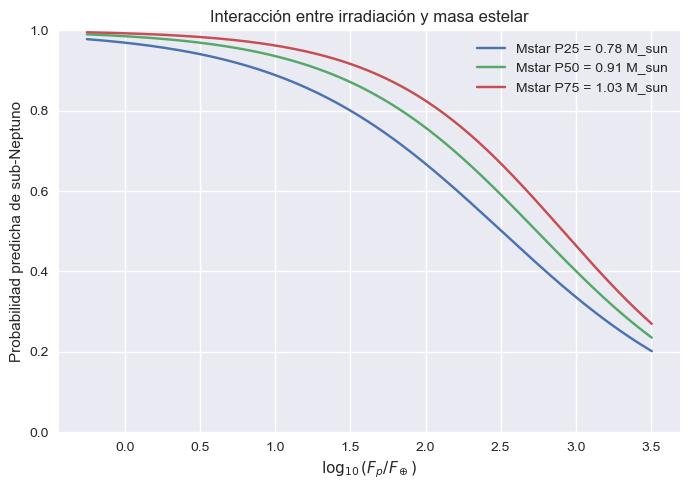

In [46]:
# Valores típicos de masa estelar: percentiles 25, 50 y 75
mstar_vals = df_interaccion_centrada["st_mass"].quantile([0.25, 0.50, 0.75])

# Rango de irradiación calculada
logF_grid = np.linspace(
    df_interaccion_centrada["log_insol_calculada"].quantile(0.01),
    df_interaccion_centrada["log_insol_calculada"].quantile(0.99),
    200
)

# Metalicidad fija en la mediana
st_met_mediana = df_interaccion_centrada["st_met"].median()

predicciones = []

for q, mstar in mstar_vals.items():
    temp = pd.DataFrame({
        "log_insol_calculada": logF_grid,
        "st_mass": mstar,
        "st_met": st_met_mediana
    })
    
    temp["logF_c"] = (
        temp["log_insol_calculada"] -
        df_interaccion_centrada["log_insol_calculada"].mean()
    )
    
    temp["Mstar_c"] = (
        temp["st_mass"] -
        df_interaccion_centrada["st_mass"].mean()
    )
    
    temp["logF_c_x_Mstar_c"] = temp["logF_c"] * temp["Mstar_c"]
    
    X_pred = sm.add_constant(
        temp[["logF_c", "Mstar_c", "logF_c_x_Mstar_c", "st_met"]],
        has_constant="add"
    )
    
    temp["prob_sub_Neptune"] = modelo_interaccion_centrada.predict(X_pred)
    temp["Mstar_label"] = f"Mstar P{int(q*100)} = {mstar:.2f} M_sun"
    
    predicciones.append(temp)

df_pred_interaccion = pd.concat(predicciones, ignore_index=True)

plt.figure(figsize=(7, 5))

for label, grupo in df_pred_interaccion.groupby("Mstar_label"):
    plt.plot(
        grupo["log_insol_calculada"],
        grupo["prob_sub_Neptune"],
        label=label
    )

plt.xlabel(r"$\log_{10}(F_p/F_\oplus)$")
plt.ylabel("Probabilidad predicha de sub-Neptuno")
plt.title("Interacción entre irradiación y masa estelar")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../figures/interaccion_insolacion_masa_estelar.png",
    dpi=300
)

plt.show()

El modelo con interacción indica que la relación entre irradiación y régimen planetario depende de la masa estelar. En todo el rango de irradiación, la probabilidad predicha de pertenecer al régimen sub-Neptuno disminuye al aumentar la irradiación. Sin embargo, para una misma irradiación, las estrellas de mayor masa presentan probabilidades predichas más altas de albergar sub-Neptunos que las estrellas de menor masa.

La interacción significativa sugiere que el efecto de la irradiación no es idéntico para todo el rango de masas estelares considerado.

In [47]:
tabla_interaccion_centrada = pd.DataFrame({
    "variable": modelo_interaccion_centrada.params.index,
    "coef": modelo_interaccion_centrada.params.values,
    "IC95_low": modelo_interaccion_centrada.conf_int()[0].values,
    "IC95_high": modelo_interaccion_centrada.conf_int()[1].values,
    "OR": np.exp(modelo_interaccion_centrada.params.values),
    "OR_IC95_low": np.exp(modelo_interaccion_centrada.conf_int()[0].values),
    "OR_IC95_high": np.exp(modelo_interaccion_centrada.conf_int()[1].values),
    "p_value": modelo_interaccion_centrada.pvalues.values
}).round(4)

tabla_interaccion_centrada.to_csv(
    "../tables/tabla_modelo_interaccion_insolacion_masa.csv",
    index=False
)

comparacion_modelos_insolacion = pd.DataFrame({
    "modelo": [
        "sin_interaccion",
        "con_interaccion"
    ],
    "formula": [
        "sub_Neptune ~ logF + Mstar + [Fe/H]",
        "sub_Neptune ~ logF * Mstar + [Fe/H]"
    ],
    "N": [
        int(modelo_rv_insol_calc.nobs),
        int(modelo_interaccion_centrada.nobs)
    ],
    "pseudo_R2": [
        modelo_rv_insol_calc.prsquared,
        modelo_interaccion_centrada.prsquared
    ],
    "AIC": [
        modelo_rv_insol_calc.aic,
        modelo_interaccion_centrada.aic
    ],
    "BIC": [
        modelo_rv_insol_calc.bic,
        modelo_interaccion_centrada.bic
    ],
    "LLR_p_value": [
        modelo_rv_insol_calc.llr_pvalue,
        modelo_interaccion_centrada.llr_pvalue
    ]
}).round(4)

comparacion_modelos_insolacion.to_csv(
    "../tables/comparacion_modelos_insolacion_interaccion.csv",
    index=False
)

tabla_interaccion_centrada, comparacion_modelos_insolacion

(           variable    coef  IC95_low  IC95_high       OR  OR_IC95_low  \
 0             const  1.3727    1.2677     1.4778   3.9461       3.5526   
 1            logF_c -1.5079   -1.6589    -1.3569   0.2214       0.1904   
 2           Mstar_c  3.6778    3.2140     4.1415  39.5581      24.8794   
 3  logF_c_x_Mstar_c -1.2560   -1.6083    -0.9036   0.2848       0.2002   
 4            st_met  0.8491    0.3302     1.3680   2.3375       1.3912   
 
    OR_IC95_high  p_value  
 0        4.3831   0.0000  
 1        0.2575   0.0000  
 2       62.8971   0.0000  
 3        0.4051   0.0000  
 4        3.9275   0.0013  ,
             modelo                              formula     N  pseudo_R2  \
 0  sin_interaccion  sub_Neptune ~ logF + Mstar + [Fe/H]  3357     0.1338   
 1  con_interaccion  sub_Neptune ~ logF * Mstar + [Fe/H]  3357     0.1458   
 
          AIC        BIC  LLR_p_value  
 0  3401.0362  3425.5114          0.0  
 1  3355.9554  3386.5494          0.0  )

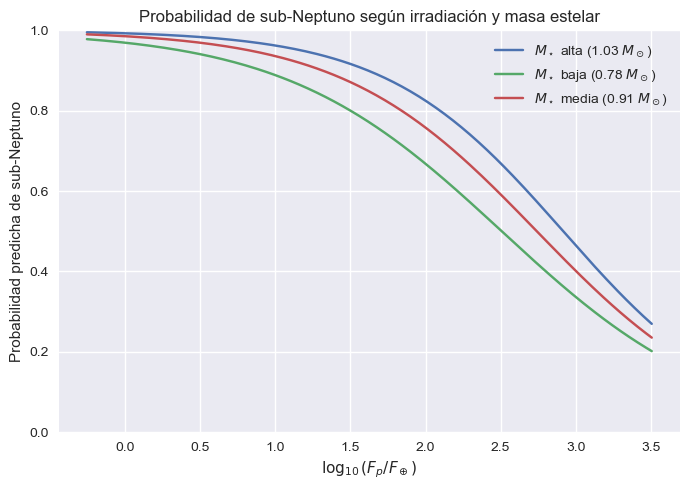

In [48]:
mstar_vals = df_interaccion_centrada["st_mass"].quantile([0.25, 0.50, 0.75])

logF_grid = np.linspace(
    df_interaccion_centrada["log_insol_calculada"].quantile(0.01),
    df_interaccion_centrada["log_insol_calculada"].quantile(0.99),
    200
)

st_met_mediana = df_interaccion_centrada["st_met"].median()

predicciones = []

for q, mstar in mstar_vals.items():
    temp = pd.DataFrame({
        "log_insol_calculada": logF_grid,
        "st_mass": mstar,
        "st_met": st_met_mediana
    })

    temp["logF_c"] = (
        temp["log_insol_calculada"] -
        df_interaccion_centrada["log_insol_calculada"].mean()
    )

    temp["Mstar_c"] = (
        temp["st_mass"] -
        df_interaccion_centrada["st_mass"].mean()
    )

    temp["logF_c_x_Mstar_c"] = temp["logF_c"] * temp["Mstar_c"]

    X_pred = sm.add_constant(
        temp[["logF_c", "Mstar_c", "logF_c_x_Mstar_c", "st_met"]],
        has_constant="add"
    )

    temp["prob_sub_Neptune"] = modelo_interaccion_centrada.predict(X_pred)

    if q == 0.25:
        label = rf"$M_\star$ baja ({mstar:.2f} $M_\odot$)"
    elif q == 0.50:
        label = rf"$M_\star$ media ({mstar:.2f} $M_\odot$)"
    else:
        label = rf"$M_\star$ alta ({mstar:.2f} $M_\odot$)"

    temp["Mstar_label"] = label
    predicciones.append(temp)

df_pred_interaccion = pd.concat(predicciones, ignore_index=True)

plt.figure(figsize=(7, 5))

for label, grupo in df_pred_interaccion.groupby("Mstar_label"):
    plt.plot(
        grupo["log_insol_calculada"],
        grupo["prob_sub_Neptune"],
        label=label
    )

plt.xlabel(r"$\log_{10}(F_p/F_\oplus)$")
plt.ylabel("Probabilidad predicha de sub-Neptuno")
plt.title("Probabilidad de sub-Neptuno según irradiación y masa estelar")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../figures/probabilidad_sub_neptune_interaccion_insolacion_masa.png",
    dpi=300
)

plt.show()

In [49]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Dataset para validación de interacción
df_validacion_interaccion = df_radius_valley[
    df_radius_valley["sub_neptune"].notna() &
    df_radius_valley["log_insol_calculada"].notna() &
    df_radius_valley["st_mass"].notna() &
    df_radius_valley["st_teff"].notna() &
    df_radius_valley["st_rad"].notna() &
    df_radius_valley["pl_orbper"].notna() &
    df_radius_valley["st_met"].notna()
].copy()

# Variables logarítmicas
df_validacion_interaccion["logP"] = np.log10(df_validacion_interaccion["pl_orbper"])

# Variables centradas
df_validacion_interaccion["logF_c"] = (
    df_validacion_interaccion["log_insol_calculada"] -
    df_validacion_interaccion["log_insol_calculada"].mean()
)

df_validacion_interaccion["Mstar_c"] = (
    df_validacion_interaccion["st_mass"] -
    df_validacion_interaccion["st_mass"].mean()
)

df_validacion_interaccion["logF_c_x_Mstar_c"] = (
    df_validacion_interaccion["logF_c"] *
    df_validacion_interaccion["Mstar_c"]
)

# 1. Matriz de correlaciones
vars_correlacion = [
    "log_insol_calculada",
    "st_mass",
    "st_teff",
    "st_rad",
    "logP",
    "st_met"
]

tabla_correlaciones_interaccion = (
    df_validacion_interaccion[vars_correlacion]
    .corr(method="spearman")
    .round(4)
)

tabla_correlaciones_interaccion.to_csv(
    "../tables/correlaciones_validacion_interaccion.csv"
)

tabla_correlaciones_interaccion

,log_insol_calculada,st_mass,st_teff,st_rad,logP,st_met
log_insol_calculada,1.0000,0.4854,0.4578,0.4922,-0.7373,0.2155
st_mass,0.4854,1.0000,0.9307,0.9371,0.1166,0.3431
st_teff,0.4578,0.9307,1.0000,0.9238,0.1553,0.1474
st_rad,0.4922,0.9371,0.9238,1.0000,0.1365,0.2737
logP,-0.7373,0.1166,0.1553,0.1365,1.0000,-0.0920
st_met,0.2155,0.3431,0.1474,0.2737,-0.0920,1.0000


In [50]:
# 2. VIF del modelo centrado con interacción

X_vif_interaccion = df_validacion_interaccion[
    [
        "logF_c",
        "Mstar_c",
        "logF_c_x_Mstar_c",
        "st_met"
    ]
].copy()

X_vif_interaccion = sm.add_constant(X_vif_interaccion)

tabla_vif_interaccion = pd.DataFrame({
    "variable": X_vif_interaccion.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_interaccion.values,
            i
        )
        for i in range(X_vif_interaccion.shape[1])
    ]
}).round(4)

tabla_vif_interaccion.to_csv(
    "../tables/vif_modelo_interaccion_insolacion_masa.csv",
    index=False
)

tabla_vif_interaccion

,variable,VIF
0,const,1.2019
1,logF_c,1.3880
2,Mstar_c,1.5523
3,logF_c_x_Mstar_c,1.1380
4,st_met,1.1058


In [51]:
# Pendiente efectiva de logF en distintos valores de masa estelar
# En el modelo centrado:
# d logit(p) / d logF_c = beta_logF + beta_interaction * Mstar_c

beta_logF = modelo_interaccion_centrada.params["logF_c"]
beta_inter = modelo_interaccion_centrada.params["logF_c_x_Mstar_c"]

mstar_percentiles = df_validacion_interaccion["st_mass"].quantile([0.20, 0.50, 0.80])

pendientes_logF = []

for q, mstar in mstar_percentiles.items():
    mstar_c = mstar - df_validacion_interaccion["st_mass"].mean()
    pendiente = beta_logF + beta_inter * mstar_c
    
    pendientes_logF.append({
        "percentil_Mstar": f"P{int(q*100)}",
        "Mstar": mstar,
        "Mstar_c": mstar_c,
        "pendiente_logF": pendiente,
        "OR_por_1dex_logF": np.exp(pendiente)
    })

tabla_pendientes_logF_por_mstar = pd.DataFrame(pendientes_logF).round(4)

tabla_pendientes_logF_por_mstar.to_csv(
    "../tables/pendiente_logF_por_masa_estelar.csv",
    index=False
)

tabla_pendientes_logF_por_mstar

,percentil_Mstar,Mstar,Mstar_c,pendiente_logF,OR_por_1dex_logF
0,P20,0.7324,-0.1496,-1.3200,0.2671
1,P50,0.9100,0.0280,-1.5430,0.2137
2,P80,1.0566,0.1746,-1.7272,0.1778


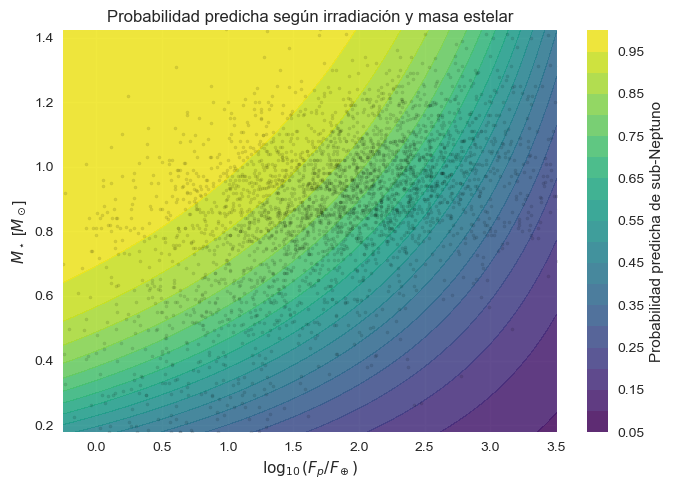

In [54]:
plt.figure(figsize=(7, 5))

contour = plt.contourf(
    logF_grid,
    Mstar_grid,
    prob_grid,
    levels=20,
    cmap="viridis",
    alpha=0.85
)

cbar = plt.colorbar(contour)
cbar.set_label("Probabilidad predicha de sub-Neptuno")

plt.scatter(
    df_validacion_interaccion["log_insol_calculada"],
    df_validacion_interaccion["st_mass"],
    s=5,
    alpha=0.10,
    color="black"
)

plt.xlabel(r"$\log_{10}(F_p/F_\oplus)$")
plt.ylabel(r"$M_\star$ [$M_\odot$]")
plt.title("Probabilidad predicha según irradiación y masa estelar")

plt.xlim(
    df_validacion_interaccion["log_insol_calculada"].quantile(0.01),
    df_validacion_interaccion["log_insol_calculada"].quantile(0.99)
)

plt.ylim(
    df_validacion_interaccion["st_mass"].quantile(0.01),
    df_validacion_interaccion["st_mass"].quantile(0.99)
)

plt.tight_layout()

plt.savefig(
    "../figures/heatmap_probabilidad_sub_neptune_logF_mstar_final.png",
    dpi=300
)

plt.show()

In [55]:
# Probabilidades predichas en puntos representativos de logF y Mstar

logF_percentiles = df_validacion_interaccion["log_insol_calculada"].quantile(
    [0.20, 0.50, 0.80]
)

mstar_percentiles = df_validacion_interaccion["st_mass"].quantile(
    [0.20, 0.50, 0.80]
)

st_met_mediana = df_validacion_interaccion["st_met"].median()

filas_pred = []

for qF, logF in logF_percentiles.items():
    for qM, mstar in mstar_percentiles.items():
        
        logF_c = logF - df_validacion_interaccion["log_insol_calculada"].mean()
        Mstar_c = mstar - df_validacion_interaccion["st_mass"].mean()
        
        temp = pd.DataFrame({
            "const": [1.0],
            "logF_c": [logF_c],
            "Mstar_c": [Mstar_c],
            "logF_c_x_Mstar_c": [logF_c * Mstar_c],
            "st_met": [st_met_mediana]
        })
        
        prob = modelo_interaccion_centrada.predict(temp)[0]
        
        filas_pred.append({
            "percentil_logF": f"P{int(qF*100)}",
            "logF": logF,
            "percentil_Mstar": f"P{int(qM*100)}",
            "Mstar": mstar,
            "prob_sub_Neptune": prob
        })

tabla_prob_predicha_representativa = pd.DataFrame(filas_pred).round(4)

tabla_prob_predicha_representativa.to_csv(
    "../tables/tabla_probabilidades_predichas_representativas.csv",
    index=False
)

tabla_prob_predicha_representativa

,percentil_logF,logF,percentil_Mstar,Mstar,prob_sub_Neptune
0,P20,1.1230,P20,0.7324,0.8448
1,P20,1.1230,P50,0.9100,0.9238
2,P20,1.1230,P80,1.0566,0.9591
3,P50,1.8381,P20,0.7324,0.6794
4,P50,1.8381,P50,0.9100,0.8009
5,P50,1.8381,P80,1.0566,0.8723
6,P80,2.4393,P20,0.7324,0.4893
7,P80,2.4393,P50,0.9100,0.6140
8,P80,2.4393,P80,1.0566,0.7074


1. A mayor irradiación, menor probabilidad predicha de sub-Neptuno.
2. A irradiación fija, mayor masa estelar implica mayor probabilidad predicha de sub-Neptuno.

Para estrellas de baja masa, la probabilidad predicha cae de 0.845 a 0.489 al pasar de baja a alta irradiación.

Para estrellas de masa mediana, cae de 0.924 a 0.614.

Para estrellas de masa alta, cae de 0.959 a 0.707.
